In [ ]:
# calling libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.stats as stats

In [ ]:
# read the movies data
movies = pd.read_csv("/content/drive/MyDrive/i2ds/hw_2/hw_2_1/movie_votes.csv")
movies

,Movie,AverageVote
0,The Shawshank Redemption,8.5
1,The Prisoner of Zenda,8.4
2,The Godfather,8.4
3,Fight Club,8.3
4,Schindler's List,8.3
...,...,...
4387,AWOL-72,2.8
4388,Def-Con 4,2.8
4389,Chairman of the Board,2.7
4390,Foodfight!,2.3


In [ ]:
# min vote for movies
mov_max = movies['AverageVote'].max()
mov_max

8.5

In [ ]:
# min vote for movies
mov_min = movies['AverageVote'].min()
mov_min

1.9

In [ ]:
# mean vote for movies
mov_mean = movies['AverageVote'].mean()
mov_mean

6.226935336976321

In [ ]:
# std_dev vote for movies
mov_std = movies['AverageVote'].std()
mov_std

0.8932148326883516

In [ ]:
# how many rows we have
mov_mount = len(movies)
mov_mount

4392

In [ ]:
# lembda
mov_lamda = 1/mov_mean
mov_lamda

0.1605926424290734

In [ ]:
# alpha

total = 0

for num in movies["AverageVote"]:
  total += np.log(num/mov_min)
mov_alpha = 1+(mov_mount/total)
mov_alpha

1.8505152700921788

In [ ]:
# movies.plot.hist(bins=100, color="red")

Text(0, 0.5, 'Count')

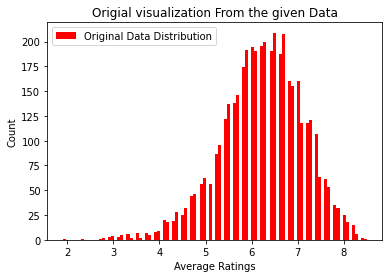

In [ ]:
plt.hist(movies['AverageVote'], bins=100, color="red")
plt.legend(labels=["Original Data Distribution"])
plt.title("Origial visualization From the given Data")
plt.xlabel("Average Ratings")
plt.ylabel("Count")

# **power law dist**

Text(0, 0.5, 'Count')

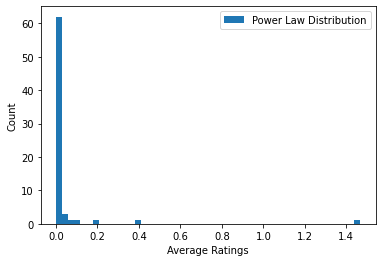

In [ ]:
#  power law dist
def powerlawDist(x,alpha,mn):
  return ((alpha-1)/mn)*((x/mn)**(-alpha))

#  power law dist
mov_powerlaw_theory = []
x = []
for i in range(1,100):
  x += [i]
  mov_powerlaw_theory += [powerlawDist(i,mov_alpha,mov_min)]

plt.hist(mov_powerlaw_theory[0:70], bins=50)
plt.legend(labels=["Power Law Distribution"])
plt.xlabel("Average Ratings")
plt.ylabel("Count")

# **exponential dist**

In [ ]:
# exponential dist
mov_lamda

0.1605926424290734

Text(0, 0.5, 'Count')

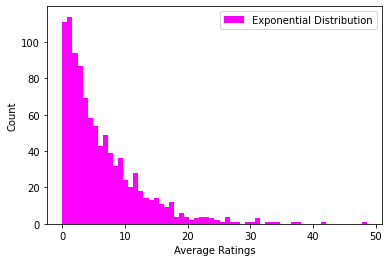

In [ ]:
# exponential dist
mov_exponential_thy = np.random.exponential(scale=1/mov_lamda, size=1000)
plt.hist(mov_exponential_thy, bins=60, color='magenta')
plt.legend(labels=["Exponential Distribution"])
plt.xlabel("Average Ratings")
plt.ylabel("Count")

# **Uniform distribution**

In [ ]:
# Uniform distribution
def uniformDist(x, mn, mx):
  return 1/(mn-mx)

In [ ]:
# Uniform distribution
mov_min

1.9

In [ ]:
# Uniform distribution
mov_max

8.5

Text(0, 0.5, 'Count')

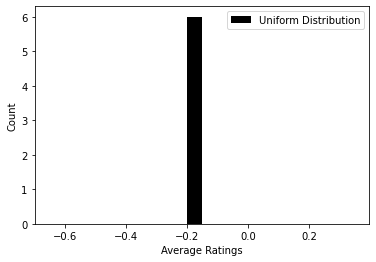

In [ ]:
# Uniform distribution

mov_uniform_thy = []
x = []
for i in range(round(mov_min),round(mov_max)):
  x += [i]
  mov_uniform_thy += [uniformDist(i,mov_min,mov_max)]

plt.hist(mov_uniform_thy, bins=20, color="black")
plt.legend(labels=["Uniform Distribution"])
plt.xlabel("Average Ratings")
plt.ylabel("Count")

# **normal distribution**

In [ ]:
# normal distribution
mov_mean

6.226935336976321

In [ ]:
# normal distribution
mov_std

0.8932148326883516

Text(0, 0.5, 'Count')

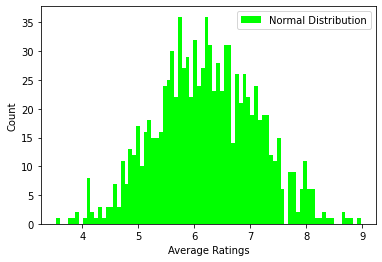

In [ ]:
# normal distribution
mov_normal_theory = np.random.normal(loc=mov_mean, scale=mov_std, size = 1000)
plt.hist(mov_normal_theory, bins=80, color="lime")
plt.legend(labels=["Normal Distribution"])
plt.xlabel("Average Ratings")
plt.ylabel("Count")

# **Discussing the airport routes data distribution**

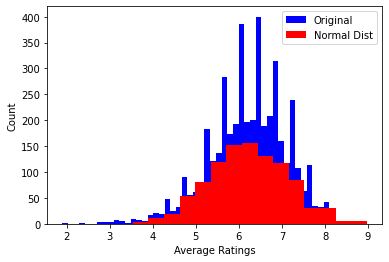

In [ ]:
x = movies['AverageVote']
y = mov_normal_theory[0:4000]
# plt.hist(mov_normal_theory, bins=80, color="lime")
plt.hist(x, label='Original', bins=50, color="blue")
plt.hist(y, label='Normal Dist', bins=15, color="red")
# plt.hist(x)
# plt.hist(y)
plt.legend(labels=["Original Vs Normal Distribution"])
plt.xlabel("Average Ratings")
plt.ylabel("Count")
plt.legend()
plt.show()